In [1]:
import sys
sys.path.append("..")

import pandas as pd
from src.alm import load_balance_sheet

In [3]:
bs = load_balance_sheet()
print(bs.shape)
print(bs.dtypes)
bs

(6, 8)
line                 str
side                 str
balance            int64
type                 str
rate             float64
reprice_share      int64
duration         float64
beta             float64
dtype: object


,line,side,balance,type,rate,reprice_share,duration,beta
0,Fixed-rate 5-yr mortgages,Asset,39,Fixed,4.38,20,3.00,NaN
1,Floating-rate commercial loans,Asset,23,Floating,4.86,100,0.25,NaN
2,Fixed-rate government bonds (7-yr),Asset,38,Fixed,3.67,20,5.00,NaN
3,Chequing and savings deposits,Liability,55,Non-maturity,0.80,100,2.50,0.3
4,Term deposits and GICs (1 to 5 yrs),Liability,35,Fixed,3.06,33,1.50,1.0
5,Short-term Wholesale Fundings,Liability,2,Floating,3.61,100,0.25,1.0


In [6]:
import importlib, src.alm
importlib.reload(src.alm)
from src.alm import *

print(interest_income(bs), interest_expense(bs), nii(bs), nim(bs), delta_nii(bs, 1))

4.220600000000001 1.5832000000000002 2.637400000000001 2.637400000000001 0.08350000000000002


In [7]:
import matplotlib.pyplot as plt
from src.alm import delta_nii, nii

shocks = [-2, -1, -0.5, 0, 0.5, 1, 2] 

scenarios = pd.DataFrame({"shock_pp": shocks})
scenarios["shock_bps"] = scenarios["shock_pp"] * 100
scenarios["delta_nii"] = [delta_nii(bs, s) for s in shocks]
scenarios["new_nii"] = [nii(bs) + delta_nii(bs, s) for s in shocks]
scenarios["pct_change"] = scenarios["delta_nii"] / nii(bs) * 100
scenarios.round(4)

,shock_pp,shock_bps,delta_nii,new_nii,pct_change
0,-2.0,-200.0,-0.1670,2.4704,-6.332
1,-1.0,-100.0,-0.0835,2.5539,-3.166
2,-0.5,-50.0,-0.0418,2.5957,-1.583
3,0.0,0.0,0.0000,2.6374,0.000
4,0.5,50.0,0.0418,2.6792,1.583
5,1.0,100.0,0.0835,2.7209,3.166
6,2.0,200.0,0.1670,2.8044,6.332


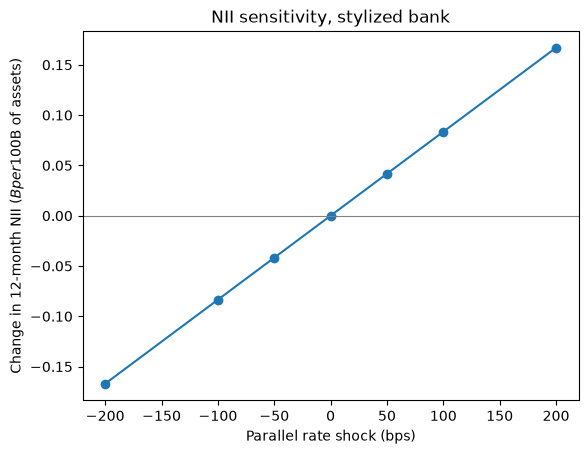

In [8]:
plt.plot(scenarios["shock_bps"], scenarios["delta_nii"], marker="o")
plt.axhline(0, color="grey", linewidth=0.8)
plt.xlabel("Parallel rate shock (bps)")
plt.ylabel("Change in 12-month NII ($B per $100B of assets)")
plt.title("NII sensitivity, stylized bank")
plt.show()